In [1]:
# BOOTSTRAP: kernel restart-dan sonra İLK işlədilən cell (CELL 1-5 əvəzinə)

import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"

import sys, re, io, json, time, platform, shutil, subprocess, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from collections import Counter

from Bio import SeqIO, AlignIO, Phylo
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord
from Bio.Phylo.TreeConstruction import DistanceCalculator, DistanceMatrix, DistanceTreeConstructor

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
REFERENCE_ACCESSIONS = ["P83483", "P83484", "Q9C5A9"]

# Layihə qovluğunu tap (cari qovluq, sonra istifadəçi qovluğu)
candidates = [
    Path("ARABIDOPSIS_ATP_SYNTHASE"),
    Path.home() / "ARABIDOPSIS_ATP_SYNTHASE",
]

PROJECT_DIR = next((p for p in candidates if (p / "data").exists()), candidates[0])

DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "results"

DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR.resolve())

# Fayllar yerindədirmi?
meta_file = DATA_DIR / "protein_metadata.csv"
fasta_file = DATA_DIR / "mitochondrial_atp_beta.fasta"
aligned_file = DATA_DIR / "mitochondrial_atp_beta_aligned.fasta"

for f in (meta_file, fasta_file, aligned_file):
    print(("OK       " if f.exists() else "MISSING  "), f)

if meta_file.exists():
    clean_df = pd.read_csv(meta_file)
    protein_data = {r["Accession"]: r for r in clean_df.to_dict("records")}
    print("clean_df loaded:", clean_df.shape)

Project directory: C:\Users\Acer\ARABIDOPSIS_ATP_SYNTHASE
OK        ARABIDOPSIS_ATP_SYNTHASE\data\protein_metadata.csv
OK        ARABIDOPSIS_ATP_SYNTHASE\data\mitochondrial_atp_beta.fasta
OK        ARABIDOPSIS_ATP_SYNTHASE\data\mitochondrial_atp_beta_aligned.fasta
clean_df loaded: (9, 9)


In [2]:
# CELL 1: INSTALL REQUIRED PYTHON PACKAGES

import sys
import subprocess

packages = [
    "requests",
    "biopython",
    "pandas",
    "numpy",
    "matplotlib",
    "seaborn",
    "scikit-learn",
    "scipy",
    "pyfamsa"          # real multiple sequence alignment (CELL 5)
]

print("Python executable:", sys.executable)

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "--upgrade", *packages
])

print("\nAll Python packages installed successfully.")

Python executable: C:\Users\Acer\.ipython\python.exe

All Python packages installed successfully.


In [1]:
import sys
import subprocess

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "--upgrade",
    "pyarrow", "numexpr", "bottleneck",
    "pandas", "scipy", "scikit-learn",
    "matplotlib", "seaborn", "biopython"
])

print("Done. Indi Kernel -> Restart et.")

Done. Indi Kernel -> Restart et.


In [1]:
# CELL 2: IMPORT LIBRARIES

import os

# Windows/joblib "physical cores < 1" xetasinin qarsisini alir (sklearn import-undan ENVEL olmalidir)
os.environ["LOKY_MAX_CPU_COUNT"] = "4"

import sys
import re
import io
import json
import time
import platform
import shutil
import subprocess
import requests
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from collections import Counter

from Bio import SeqIO, AlignIO, Phylo
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord
from Bio.Phylo.TreeConstruction import (
    DistanceCalculator,
    DistanceMatrix,
    DistanceTreeConstructor
)

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

# NOTE: scipy.stats.entropy artiq import edilmir (CELL 6-da adi ile toqqusurdu)
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

# Project folders

PROJECT_DIR = Path("ARABIDOPSIS_ATP_SYNTHASE")

DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "results"

DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Python version:", sys.version)
print("Operating system:", platform.system())
print("Project directory:", PROJECT_DIR.resolve())

print("\nAll imports completed successfully.")

Python version: 3.12.7 | packaged by Anaconda, Inc. | (main, Oct  4 2024, 13:17:27) [MSC v.1929 64 bit (AMD64)]
Operating system: Windows
Project directory: C:\Users\Acer\ARABIDOPSIS_ATP_SYNTHASE

All imports completed successfully.


In [2]:
# CELL 3: ROBUST UNIPROT DATA RETRIEVAL
# Target: Arabidopsis thaliana mitochondrial ATP synthase beta

BASE_URL = "https://rest.uniprot.org"
HEADERS = {
    "User-Agent": "Arabidopsis-ATP-Research/1.0",
    "Accept": "application/json"
}

REFERENCE_ACCESSIONS = ["P83483", "P83484", "Q9C5A9"]

session = requests.Session()
session.headers.update(HEADERS)


def safe_get(url, params=None, retries=3):

    for attempt in range(retries):

        try:
            response = session.get(url, params=params, timeout=90)

            if response.status_code == 200:
                return response

            # Do not repeatedly retry invalid requests
            if response.status_code in [400, 404]:
                raise RuntimeError(
                    f"HTTP {response.status_code}\n"
                    f"URL: {response.url}\n"
                    f"Server response: {response.text[:1500]}"
                )

            response.raise_for_status()

        except requests.RequestException as error:

            if attempt == retries - 1:
                raise RuntimeError(f"Connection failed: {error}")

            time.sleep(3 * (attempt + 1))


def parse_entry(entry):

    accession = entry.get("primaryAccession")

    sequence = entry.get("sequence", {}).get("value", "")

    protein_description = entry.get("proteinDescription", {})

    recommended = protein_description.get("recommendedName", {})

    protein_name = recommended.get("fullName", {}).get("value", "")

    if not protein_name:
        names = protein_description.get("submissionNames", [])
        if names:
            protein_name = names[0].get("fullName", {}).get("value", "")

    organism = entry.get("organism", {}).get("scientificName", "Unknown")

    taxid = entry.get("organism", {}).get("taxonId")

    # FIX: UniProt bu zulallar ucun geneName yox, orderedLocusNames saxlayir
    genes = entry.get("genes", [])
    gene = "Unknown"

    if genes:
        g = genes[0]
        gene = (
            g.get("geneName", {}).get("value")
            or (g.get("orderedLocusNames") or [{}])[0].get("value")
            or (g.get("orfNames") or [{}])[0].get("value")
            or "Unknown"
        )

    # Subcellular location annotation
    locations = []

    for comment in entry.get("comments", []):

        if comment.get("commentType") == "SUBCELLULAR LOCATION":

            for sublocation in comment.get("subcellularLocations", []):

                location = sublocation.get("location", {}).get("value", "")
                locations.append(location)

    return {
        "Accession": accession,
        "Protein": protein_name,
        "Organism": organism,
        "TaxID": taxid,
        "Gene": gene,
        "Sequence": sequence,
        "Length": len(sequence),
        "Localization": "; ".join(locations),
        "Source": "UniProt"
    }


# STEP 1: Download three verified Arabidopsis references

protein_data = {}

print("STEP 1: Downloading Arabidopsis reference proteins...")

for accession in REFERENCE_ACCESSIONS:

    url = f"{BASE_URL}/uniprotkb/{accession}.json"

    response = safe_get(url)

    entry = response.json()

    parsed = parse_entry(entry)

    if parsed["Organism"] != "Arabidopsis thaliana":
        raise ValueError(f"Unexpected organism for {accession}")

    if not parsed["Sequence"]:
        raise ValueError(f"Missing sequence for {accession}")

    if not parsed["Protein"]:
        raise ValueError(f"Missing protein annotation for {accession}")

    if not parsed["Localization"]:
        raise ValueError(f"Missing localization annotation for {accession}")

    if not parsed["Sequence"].isalpha():
        raise ValueError(f"Invalid sequence for {accession}")

    protein_data[accession] = parsed

    print(
        accession, "|", parsed["Protein"],
        "| Gene:", parsed["Gene"],
        "| Length:", parsed["Length"]
    )


# STEP 2: Search additional green plant mitochondrial homologs
# Birinci sorgu deqiqdir (Swiss-Prot + mitochondrial adi).
# Ugursuz olarsa, kohne sorguya qayidir.

print("\nSTEP 2: Searching additional plant homologs...")

search_queries = [
    (
        'taxonomy_id:33090 AND reviewed:true AND '
        'protein_name:"ATP synthase subunit beta, mitochondrial"'
    ),
    (
        'taxonomy_id:33090 AND '
        'protein_name:"ATP synthase subunit beta"'
    ),
]

added = 0

for search_query in search_queries:

    try:
        response = safe_get(
            f"{BASE_URL}/uniprotkb/search",
            params={"query": search_query, "format": "json", "size": 500}
        )

        search_results = response.json().get("results", [])

        print("Query:", search_query)
        print("Search results received:", len(search_results))

        for entry in search_results:

            parsed = parse_entry(entry)

            accession = parsed["Accession"]

            if not accession or not parsed["Sequence"]:
                continue

            if not parsed["Sequence"].isalpha():
                continue

            # Keep only mitochondrial ATP synthase beta proteins
            is_mito = (
                "mitochondrial" in parsed["Protein"].lower()
                or "mitochondrion" in parsed["Localization"].lower()
            )

            if not is_mito:
                continue

            if not 400 <= parsed["Length"] <= 700:
                continue

            if accession not in protein_data:
                added += 1

            protein_data[accession] = parsed

        if added > 0:
            break

    except Exception as error:
        print("Additional homolog search was unsuccessful:")
        print(error)

if added == 0:
    print("No additional homologs found; the three Arabidopsis references are retained.")


# STEP 3: Verify reference proteins

for accession in REFERENCE_ACCESSIONS:
    assert accession in protein_data, f"Reference missing: {accession}"


# STEP 4: Create dataframe

data_df = pd.DataFrame(list(protein_data.values()))

data_df = data_df.drop_duplicates(subset="Accession").reset_index(drop=True)


# STEP 5: Save raw data

data_df.to_csv(DATA_DIR / "protein_metadata_raw.csv", index=False)


# STEP 6: Display results

print("\n" + "=" * 60)
print("UNIPROT DATA RETRIEVAL COMPLETED")
print("=" * 60)

print("Total unique proteins:", len(data_df))
print("Number of organisms:", data_df["Organism"].nunique())

print("\nArabidopsis reference proteins:")

display(
    data_df[data_df["Accession"].isin(REFERENCE_ACCESSIONS)]
    [["Accession", "Protein", "Organism", "Gene", "Length"]]
)

print("\nAdditional mitochondrial homologs:")

display(
    data_df[~data_df["Accession"].isin(REFERENCE_ACCESSIONS)]
    [["Accession", "Protein", "Organism", "Length"]]
    .head(15)
)

STEP 1: Downloading Arabidopsis reference proteins...
P83483 | ATP synthase subunit beta-1, mitochondrial | Gene: At5g08670 | Length: 556
P83484 | ATP synthase subunit beta-2, mitochondrial | Gene: At5g08690 | Length: 556
Q9C5A9 | ATP synthase subunit beta-3, mitochondrial | Gene: At5g08680 | Length: 559

STEP 2: Searching additional plant homologs...
Query: taxonomy_id:33090 AND reviewed:true AND protein_name:"ATP synthase subunit beta, mitochondrial"
Search results received: 10

UNIPROT DATA RETRIEVAL COMPLETED
Total unique proteins: 9
Number of organisms: 7

Arabidopsis reference proteins:


,Accession,Protein,Organism,Gene,Length
0,P83483,"ATP synthase subunit beta-1, mitochondrial",Arabidopsis thaliana,At5g08670,556
1,P83484,"ATP synthase subunit beta-2, mitochondrial",Arabidopsis thaliana,At5g08690,556
2,Q9C5A9,"ATP synthase subunit beta-3, mitochondrial",Arabidopsis thaliana,At5g08680,559



Additional mitochondrial homologs:


,Accession,Protein,Organism,Length
3,Q01859,"ATP synthase subunit beta, mitochondrial",Oryza sativa subsp. japonica,552
4,P19023,"ATP synthase subunit beta, mitochondrial",Zea mays,553
5,P29685,"ATP synthase subunit beta, mitochondrial",Hevea brasiliensis,562
6,P17614,"ATP synthase subunit beta, mitochondrial",Nicotiana plumbaginifolia,560
7,P37399,"ATP synthase subunit beta, mitochondrial",Daucus carota,547
8,P38482,"ATP synthase subunit beta, mitochondrial",Chlamydomonas reinhardtii,574


In [3]:
# CELL 4: SEQUENCE QUALITY CONTROL

VALID_AA = set("ACDEFGHIKLMNPQRSTVWY")

clean_data = []

seen_sequences = set()

for accession, row in protein_data.items():

    sequence = row["Sequence"].upper()

    # Length filter
    if not 400 <= len(sequence) <= 700:
        continue

    # Remove ambiguous amino acid sequences
    if not set(sequence).issubset(VALID_AA):
        continue

    # Avoid exact duplicate sequences
    if sequence in seen_sequences:
        continue

    seen_sequences.add(sequence)

    clean_data.append({**row, "Sequence": sequence})


clean_df = pd.DataFrame(clean_data)

# Ensure all three reference proteins survived QC
for accession in REFERENCE_ACCESSIONS:

    if accession not in clean_df["Accession"].values:
        raise ValueError(f"Reference {accession} did not pass QC.")

# Reference-lar hemise ilk siradadir (alignment ucun vacibdir)
clean_df["is_ref"] = clean_df["Accession"].isin(REFERENCE_ACCESSIONS)
clean_df = (
    clean_df.sort_values("is_ref", ascending=False, kind="stable")
    .drop(columns="is_ref")
    .reset_index(drop=True)
)

print("Sequences after quality control:", len(clean_df))

print("\nOrganisms represented:")
print(clean_df["Organism"].nunique())

print("\nSequence length summary:")
display(clean_df["Length"].describe())

print("\nArabidopsis references:")
display(
    clean_df[clean_df["Accession"].isin(REFERENCE_ACCESSIONS)]
    [["Accession", "Gene", "Length"]]
)


# Save data

clean_df.to_csv(DATA_DIR / "protein_metadata.csv", index=False)

records = [
    SeqRecord(
        Seq(row["Sequence"]),
        id=row["Accession"],
        description=row["Organism"]
    )
    for _, row in clean_df.iterrows()
]

SeqIO.write(records, DATA_DIR / "mitochondrial_atp_beta.fasta", "fasta")

print("\nQC completed successfully.")

Sequences after quality control: 9

Organisms represented:
7

Sequence length summary:


count      9.000000
mean     557.666667
std        7.632169
min      547.000000
25%      553.000000
50%      556.000000
75%      560.000000
max      574.000000
Name: Length, dtype: float64


Arabidopsis references:


,Accession,Gene,Length
0,P83483,At5g08670,556
1,P83484,At5g08690,556
2,Q9C5A9,At5g08680,559



QC completed successfully.


In [ ]:
# CELL 5: MULTIPLE SEQUENCE ALIGNMENT (PyFAMSA) - robust version

import traceback
from pyfamsa import Aligner, Sequence

input_fasta = DATA_DIR / "mitochondrial_atp_beta.fasta"
aligned_fasta = DATA_DIR / "mitochondrial_atp_beta_aligned.fasta"

records = list(SeqIO.parse(str(input_fasta), "fasta"))

print("Input sequences:", len(records))

if len(records) < 2:
    raise ValueError("At least two protein sequences are required.")

sequences = [
    Sequence(r.id.encode(), str(r.seq).encode())
    for r in records
]

# Əvvəl UPGMA, alınmasa default parametrlər
msa = None

for kwargs in ({"guide_tree": "upgma"}, {}):
    try:
        msa = Aligner(**kwargs).align(sequences)
        print("Aligner parameters used:", kwargs or "default")
        break
    except Exception:
        print("Aligner failed with parameters:", kwargs)
        traceback.print_exc()

if msa is None:
    raise RuntimeError("PyFAMSA alignment failed with all parameter sets.")

print("Sequences returned by PyFAMSA:", len(msa))


def to_text(value):
    return value.decode() if isinstance(value, bytes) else str(value)


aligned = {to_text(s.id): to_text(s.sequence) for s in msa}

missing = [r.id for r in records if r.id not in aligned]

if missing:
    raise ValueError(f"PyFAMSA did not return these sequences: {missing}")

# Orijinal sırani qoru
aligned_records = [
    SeqRecord(Seq(aligned[r.id]), id=r.id, description=r.description)
    for r in records
]

lengths = {len(r.seq) for r in aligned_records}

if len(lengths) != 1:
    raise ValueError("Alignment sequences have unequal lengths.")

SeqIO.write(aligned_records, str(aligned_fasta), "fasta")

print("Multiple sequence alignment completed!")
print("Number of sequences:", len(aligned_records))
print("Alignment length:", lengths.pop())
print("Saved:", aligned_fasta)

Input sequences: 9


Shannon entropy analysis completed!
   Position  Shannon_Entropy  Gap_Fraction
0         1         0.000000           0.0
1         2         0.503258           0.0
2         3         0.503258           0.0
3         4         0.503258           0.0
4         5         0.503258           0.0
Columns excluded (gap-rich): 93


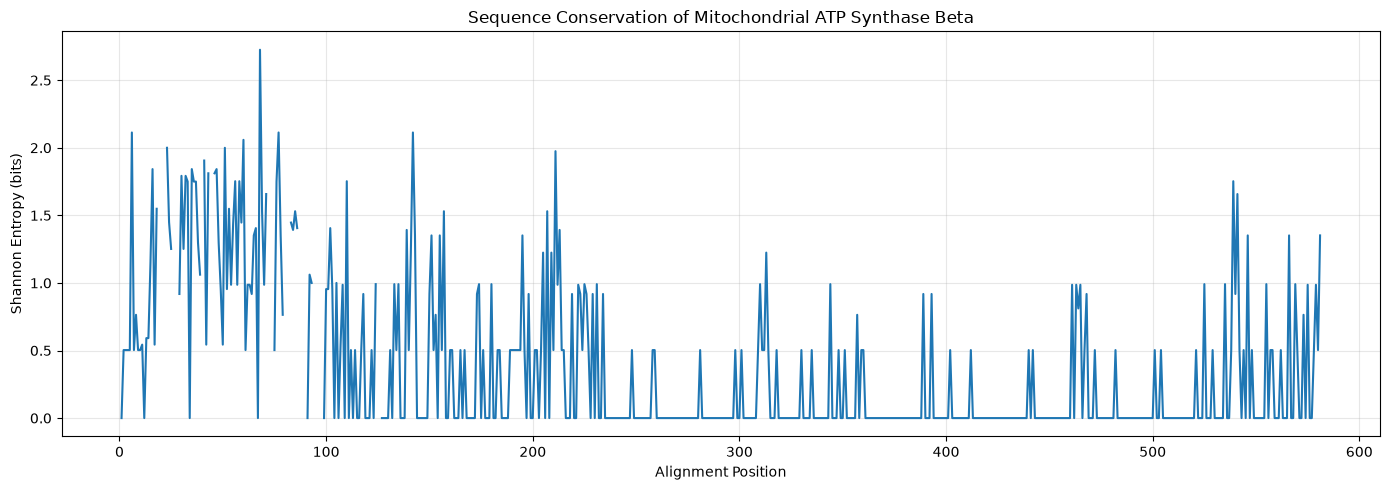

In [2]:
# CELL 6: SHANNON ENTROPY ANALYSIS

aligned_fasta = DATA_DIR / "mitochondrial_atp_beta_aligned.fasta"

# Read aligned sequences
alignment = AlignIO.read(str(aligned_fasta), "fasta")

alignment_length = alignment.get_alignment_length()

GAP_CUTOFF = 0.5   # sutunun >50%-i gap-dirsa entropy hesablanmir

entropy_scores = []
gap_fractions = []

for position in range(alignment_length):

    column = alignment[:, position]

    gap_fraction = column.count("-") / len(column)
    gap_fractions.append(gap_fraction)

    residues = [aa for aa in column if aa not in ("-", "X", "?")]

    if gap_fraction > GAP_CUTOFF or len(residues) == 0:
        entropy_scores.append(np.nan)
        continue

    counts = Counter(residues)
    probabilities = np.array(list(counts.values())) / len(residues)

    h = -np.sum(probabilities * np.log2(probabilities))

    entropy_scores.append(abs(h))   # -0.0 problemi yox olur

entropy_df = pd.DataFrame({
    "Position": range(1, alignment_length + 1),
    "Shannon_Entropy": entropy_scores,
    "Gap_Fraction": gap_fractions
})

# Save results
entropy_df.to_csv(DATA_DIR / "shannon_entropy.csv", index=False)

print("Shannon entropy analysis completed!")
print(entropy_df.head())
print("Columns excluded (gap-rich):", int(entropy_df["Shannon_Entropy"].isna().sum()))

# Visualization
plt.figure(figsize=(14, 5))

plt.plot(entropy_df["Position"], entropy_df["Shannon_Entropy"])

plt.xlabel("Alignment Position")
plt.ylabel("Shannon Entropy (bits)")
plt.title("Sequence Conservation of Mitochondrial ATP Synthase Beta")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "shannon_entropy.png", dpi=300)
plt.show()

In [3]:
# CELL 7: PROTEIN FEATURE EXTRACTION

AMINO_ACIDS = "ACDEFGHIKLMNPQRSTVWY"

DIPEPTIDES = [a + b for a in AMINO_ACIDS for b in AMINO_ACIDS]


def extract_features(sequence):

    sequence = str(sequence)

    features = {}

    # Amino acid composition
    aa_counts = Counter(sequence)

    for aa in AMINO_ACIDS:
        features[f"AA_{aa}"] = aa_counts[aa] / len(sequence)

    # Dipeptide composition
    pairs = [sequence[i:i + 2] for i in range(len(sequence) - 1)]

    pair_counts = Counter(pairs)

    total_pairs = len(pairs)

    for pair in DIPEPTIDES:
        features[f"DI_{pair}"] = pair_counts[pair] / total_pairs

    return features


feature_rows = []
protein_ids = []

for record in alignment:

    # FIX: gap ("-") simvollarini at, yalniz real ardicilliqdan feature cixar
    ungapped = str(record.seq).replace("-", "")

    feature_rows.append(extract_features(ungapped))
    protein_ids.append(record.id)


feature_df = pd.DataFrame(feature_rows, index=protein_ids)

print("Feature matrix:", feature_df.shape)

display(feature_df.iloc[:5, :10])

feature_df.to_csv(RESULTS_DIR / "protein_feature_matrix.csv")

Feature matrix: (9, 420)


,AA_A,AA_C,AA_D,AA_E,AA_F,AA_G,AA_H,AA_I,AA_K,AA_L
P83483,0.098921,0.005396,0.053957,0.062950,0.025180,0.097122,0.019784,0.061151,0.046763,0.097122
P83484,0.098921,0.005396,0.053957,0.062950,0.025180,0.095324,0.019784,0.061151,0.046763,0.097122
Q9C5A9,0.093023,0.005367,0.053667,0.062612,0.025045,0.100179,0.019678,0.064401,0.046512,0.098390
Q01859,0.108696,0.003623,0.050725,0.063406,0.032609,0.101449,0.019928,0.059783,0.041667,0.090580
P19023,0.108499,0.003617,0.052441,0.061483,0.032550,0.095841,0.018083,0.063291,0.043400,0.088608


PCA explained variance: [0.32402533 0.23648737]
Total explained variance: 0.5605126982977264


  File "C:\Users\Acer\.ipython\Lib\site-packages\joblib\externals\loky\backend\context.py", line 282, in _count_physical_cores
    raise ValueError(f"found {cpu_count_physical} physical cores < 1")


Optimal clusters: 2
Silhouette scores: {2: 0.315, 3: 0.23, 4: 0.263, 5: 0.271, 6: 0.269}
Silhouette score (optimal): 0.31549435588542046


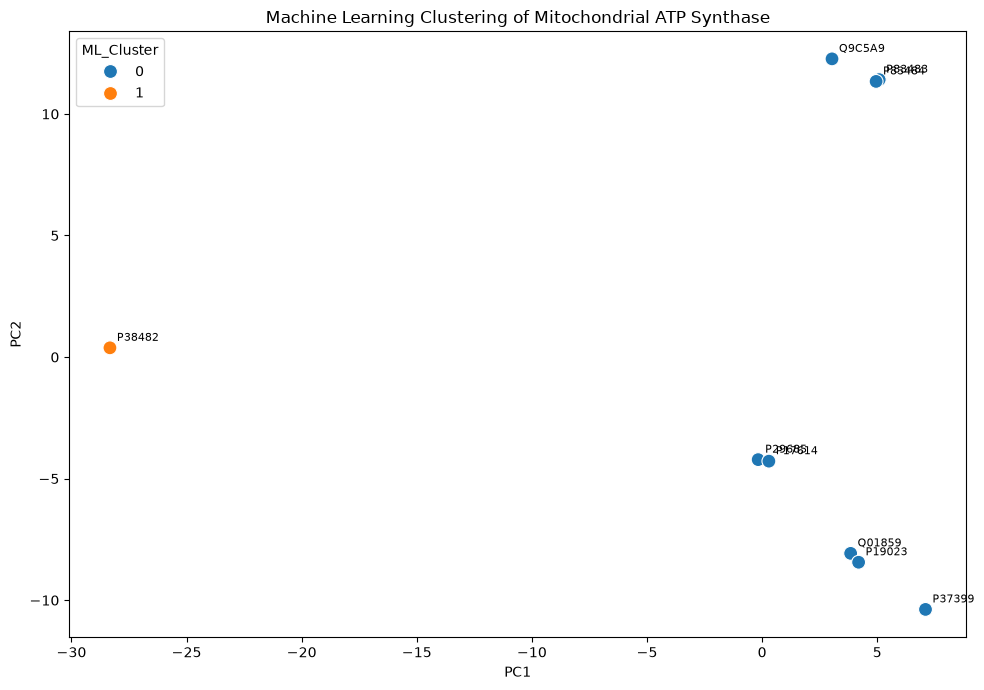

,Accession,Organism,ML_Cluster,PC1,PC2
0,P83483,Arabidopsis thaliana,0,5.085124,11.410779
1,P83484,Arabidopsis thaliana,0,4.950609,11.337482
2,Q9C5A9,Arabidopsis thaliana,0,3.035802,12.264900
3,Q01859,Oryza sativa subsp. japonica,0,3.845492,-8.074325
4,P19023,Zea mays,0,4.191005,-8.439388
5,P29685,Hevea brasiliensis,0,-0.171879,-4.218566
6,P17614,Nicotiana plumbaginifolia,0,0.294409,-4.281565
7,P37399,Daucus carota,0,7.096831,-10.379518
8,P38482,Chlamydomonas reinhardtii,1,-28.327393,0.380200


In [4]:
# CELL 8: PCA AND K-MEANS

if len(feature_df) < 3:
    raise ValueError("At least 3 sequences are required.")


scaler = StandardScaler()

X_scaled = scaler.fit_transform(feature_df)


# PCA

pca = PCA(n_components=2, random_state=RANDOM_STATE)

X_pca = pca.fit_transform(X_scaled)

print("PCA explained variance:", pca.explained_variance_ratio_)
print("Total explained variance:", pca.explained_variance_ratio_.sum())


# K-Means optimization

max_k = min(6, len(feature_df) - 1)

silhouette_results = {}

for k in range(2, max_k + 1):

    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)

    labels = model.fit_predict(X_scaled)

    if len(np.unique(labels)) < 2:
        continue

    silhouette_results[k] = silhouette_score(X_scaled, labels)


if not silhouette_results:
    raise ValueError("K-Means could not produce valid clusters.")


optimal_k = max(silhouette_results, key=silhouette_results.get)


final_model = KMeans(n_clusters=optimal_k, random_state=RANDOM_STATE, n_init=20)

clusters = final_model.fit_predict(X_scaled)


organism_lookup = clean_df.set_index("Accession")["Organism"]

ml_results = pd.DataFrame({
    "Accession": protein_ids,
    "Organism": [organism_lookup[a] for a in protein_ids],
    "ML_Cluster": clusters,
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1]
})


print("Optimal clusters:", optimal_k)
print("Silhouette scores:", {k: round(v, 3) for k, v in silhouette_results.items()})
print("Silhouette score (optimal):", silhouette_results[optimal_k])


plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=ml_results,
    x="PC1",
    y="PC2",
    hue="ML_Cluster",
    palette="tab10",
    s=100
)

for _, r in ml_results.iterrows():
    plt.annotate(r["Accession"], (r["PC1"], r["PC2"]),
                 textcoords="offset points", xytext=(5, 5), fontsize=8)

plt.title("Machine Learning Clustering of Mitochondrial ATP Synthase")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "ML_PCA_clusters.png", dpi=300)
plt.show()

display(ml_results)

ml_results.to_csv(RESULTS_DIR / "ML_results.csv", index=False)

In [5]:
# CELL 9: PHYLOGENETIC TREE

iqtree_path = shutil.which("iqtree2") or shutil.which("iqtree")

tree_path = RESULTS_DIR / "mitochondrial_ATP_tree.nwk"


if iqtree_path is not None:

    print("IQ-TREE detected.")

    prefix = str(RESULTS_DIR / "atp_phylogeny")

    command = [
        iqtree_path,
        "-s", str(aligned_fasta),
        "-m", "MFP",
        "-B", "1000",
        "--alrt", "1000",
        "-T", "AUTO",
        "--prefix", prefix
    ]

    result = subprocess.run(
        command, capture_output=True, text=True, timeout=3600
    )

    generated_tree = Path(prefix + ".treefile")

    if result.returncode == 0 and generated_tree.exists():

        shutil.copy2(generated_tree, tree_path)

        phylogeny_method = "IQ-TREE Maximum Likelihood"

    else:

        print("IQ-TREE failed. Using NJ fallback.")
        print(result.stderr[-2000:])

        iqtree_path = None


if iqtree_path is None:

    print("Building Neighbor Joining tree...")

    # FIX: gap-gap cutlerini "uygunluq" saymayan p-distance
    ids = [r.id for r in alignment]
    seqs = [str(r.seq) for r in alignment]

    def p_distance(a, b):
        pairs = [(x, y) for x, y in zip(a, b) if x != "-" and y != "-"]
        if not pairs:
            return 1.0
        return 1 - sum(x == y for x, y in pairs) / len(pairs)

    lower = [
        [0.0 if i == j else p_distance(seqs[i], seqs[j]) for j in range(i + 1)]
        for i in range(len(ids))
    ]

    dm = DistanceMatrix(ids, lower)

    tree = DistanceTreeConstructor().nj(dm)

    Phylo.write(tree, str(tree_path), "newick")

    phylogeny_method = "Neighbor Joining (p-distance, gaps ignored)"


tree = Phylo.read(str(tree_path), "newick")

assert len(tree.get_terminals()) == len(alignment)

print("\nPhylogenetic tree generated!")
print("Method:", phylogeny_method)
print("Number of taxa:", len(tree.get_terminals()))
print("Tree file:", tree_path)

Building Neighbor Joining tree...

Phylogenetic tree generated!
Method: Neighbor Joining (p-distance, gaps ignored)
Number of taxa: 9
Tree file: ARABIDOPSIS_ATP_SYNTHASE\results\mitochondrial_ATP_tree.nwk


In [6]:
# CELL 10: PHYLOGENETIC VALIDATION

tree_taxa = [terminal.name for terminal in tree.get_terminals()]

common_ids = [a for a in protein_ids if a in tree_taxa]

if len(common_ids) < 3:
    raise ValueError("Not enough matching taxa for validation.")


# Pairwise phylogenetic distance matrix

n = len(common_ids)

phylo_dist = np.zeros((n, n))

for i in range(n):
    for j in range(i + 1, n):

        distance = tree.distance(common_ids[i], common_ids[j])

        phylo_dist[i, j] = max(0, distance)
        phylo_dist[j, i] = phylo_dist[i, j]


# Hierarchical clustering

condensed = squareform(phylo_dist, checks=False)

phylo_linkage = linkage(condensed, method="average")

phylo_clusters = fcluster(phylo_linkage, t=optimal_k, criterion="maxclust")


# ML cluster assignments

ml_lookup = dict(zip(ml_results["Accession"], ml_results["ML_Cluster"]))

ml_labels = [ml_lookup[a] for a in common_ids]


# ARI

ari = adjusted_rand_score(ml_labels, phylo_clusters)


# Permutation test: ARI sans seviyyesinden yuksekdirmi?

rng = np.random.default_rng(RANDOM_STATE)

perm = np.array([
    adjusted_rand_score(rng.permutation(ml_labels), phylo_clusters)
    for _ in range(10000)
])

p_value = (np.sum(perm >= ari) + 1) / (len(perm) + 1)


validation_df = pd.DataFrame({
    "Accession": common_ids,
    "ML_Cluster": ml_labels,
    "Phylogenetic_Cluster": phylo_clusters
})


print("Adjusted Rand Index:", round(ari, 4))
print("Permutation p-value:", round(p_value, 4))
print("Cluster sizes (ML):", dict(Counter(ml_labels)))
print("Cluster sizes (Phylo):", dict(Counter(phylo_clusters)))

display(validation_df)

validation_df.to_csv(RESULTS_DIR / "ML_phylogenetic_validation.csv", index=False)

Adjusted Rand Index: 1.0
Permutation p-value: 0.1086
Cluster sizes (ML): {0: 8, 1: 1}
Cluster sizes (Phylo): {np.int32(1): 8, np.int32(2): 1}


,Accession,ML_Cluster,Phylogenetic_Cluster
0,P83483,0,1
1,P83484,0,1
2,Q9C5A9,0,1
3,Q01859,0,1
4,P19023,0,1
5,P29685,0,1
6,P17614,0,1
7,P37399,0,1
8,P38482,1,2


In [19]:
# CELL 11: CHECK TAXONOMY AND PROTEIN IDENTITIES

print("Available columns:")
print(clean_df.columns.tolist())

# FIX: QC-den kecmis data (clean_df) gosterilir
display(
    clean_df[["Accession", "Protein", "Organism", "Gene", "TaxID", "Length"]]
    .drop_duplicates()
)

Available columns:
['Accession', 'Protein', 'Organism', 'TaxID', 'Gene', 'Sequence', 'Length', 'Localization', 'Source']


,Accession,Protein,Organism,TaxID,Length
0,P83483,"ATP synthase subunit beta-1, mitochondrial",Arabidopsis thaliana,3702,556
1,P83484,"ATP synthase subunit beta-2, mitochondrial",Arabidopsis thaliana,3702,556
2,Q9C5A9,"ATP synthase subunit beta-3, mitochondrial",Arabidopsis thaliana,3702,559
3,Q01859,"ATP synthase subunit beta, mitochondrial",Oryza sativa subsp. japonica,39947,552
4,P19023,"ATP synthase subunit beta, mitochondrial",Zea mays,4577,553
5,P29685,"ATP synthase subunit beta, mitochondrial",Hevea brasiliensis,3981,562
6,P17614,"ATP synthase subunit beta, mitochondrial",Nicotiana plumbaginifolia,4092,560
7,P37399,"ATP synthase subunit beta, mitochondrial",Daucus carota,4039,547
8,P38482,"ATP synthase subunit beta, mitochondrial",Chlamydomonas reinhardtii,3055,574


In [7]:
# CELL 12: PAIRWISE SEQUENCE IDENTITY

from Bio.Align import PairwiseAligner, substitution_matrices

# FIX: zulal ucun BLOSUM62 (match/mismatch skorlari DNT ucundur)
aligner = PairwiseAligner()
aligner.mode = "global"
aligner.substitution_matrix = substitution_matrices.load("BLOSUM62")
aligner.open_gap_score = -10
aligner.extend_gap_score = -0.5

arabidopsis_ids = REFERENCE_ACCESSIONS

# FIX: data_df yox, clean_df
reference_records = {
    row["Accession"]: row["Sequence"]
    for _, row in clean_df.iterrows()
    if row["Accession"] in arabidopsis_ids
}

identity_results = []

for _, row in clean_df.iterrows():

    sequence = row["Sequence"]

    for ref_id, ref_sequence in reference_records.items():

        alignment_pair = aligner.align(ref_sequence, sequence)[0]

        coordinates = alignment_pair.coordinates

        identical = 0
        aligned_positions = 0   # alignment uzunlugu (gap-lar daxil)

        for i in range(len(coordinates[0]) - 1):

            r0, r1 = coordinates[0][i:i + 2]
            s0, s1 = coordinates[1][i:i + 2]

            if r1 > r0 and s1 > s0:

                for a, b in zip(ref_sequence[r0:r1], sequence[s0:s1]):
                    aligned_positions += 1
                    if a == b:
                        identical += 1

            elif r1 > r0:
                aligned_positions += r1 - r0

            elif s1 > s0:
                aligned_positions += s1 - s0

        identity = (
            100 * identical / aligned_positions
            if aligned_positions else np.nan
        )

        identity_results.append({
            "Accession": row["Accession"],
            "Organism": row["Organism"],
            "Reference": ref_id,
            "Sequence_Identity_Percent": round(identity, 2)
        })

identity_df = pd.DataFrame(identity_results)

display(identity_df)

identity_df.to_csv(DATA_DIR / "pairwise_sequence_identity.csv", index=False)

print("Pairwise sequence identity analysis completed!")

,Accession,Organism,Reference,Sequence_Identity_Percent
0,P83483,Arabidopsis thaliana,P83483,100.00
1,P83483,Arabidopsis thaliana,P83484,99.82
2,P83483,Arabidopsis thaliana,Q9C5A9,96.96
3,P83484,Arabidopsis thaliana,P83483,99.82
4,P83484,Arabidopsis thaliana,P83484,100.00
5,P83484,Arabidopsis thaliana,Q9C5A9,96.78
6,Q9C5A9,Arabidopsis thaliana,P83483,96.96
7,Q9C5A9,Arabidopsis thaliana,P83484,96.78
8,Q9C5A9,Arabidopsis thaliana,Q9C5A9,100.00
9,Q01859,Oryza sativa subsp. japonica,P83483,82.71


Pairwise sequence identity analysis completed!


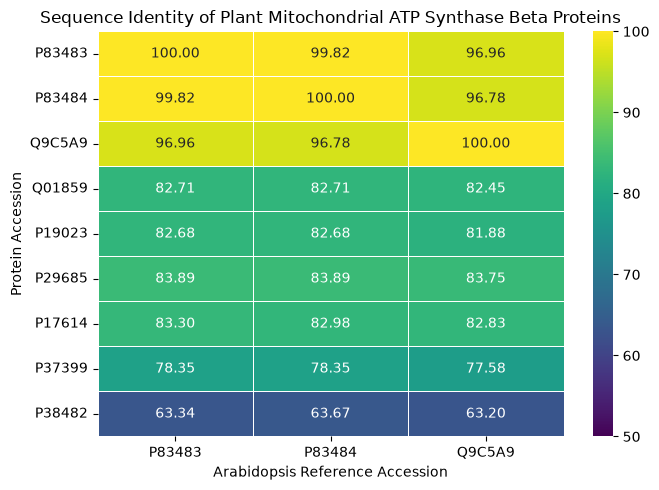

In [8]:
# CELL 13: SEQUENCE IDENTITY HEATMAP

heatmap_data = identity_df.pivot(
    index="Accession",
    columns="Reference",
    values="Sequence_Identity_Percent"
)

# Setir ve sutun siralamasi: reference-lar yuxarida
heatmap_data = heatmap_data.loc[clean_df["Accession"], REFERENCE_ACCESSIONS]

plt.figure(figsize=(7, 5))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".2f",
    cmap="viridis",
    vmin=50,
    vmax=100,
    linewidths=0.5
)

plt.title("Sequence Identity of Plant Mitochondrial ATP Synthase Beta Proteins")

plt.xlabel("Arabidopsis Reference Accession")
plt.ylabel("Protein Accession")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "identity_heatmap.png", dpi=300)
plt.show()

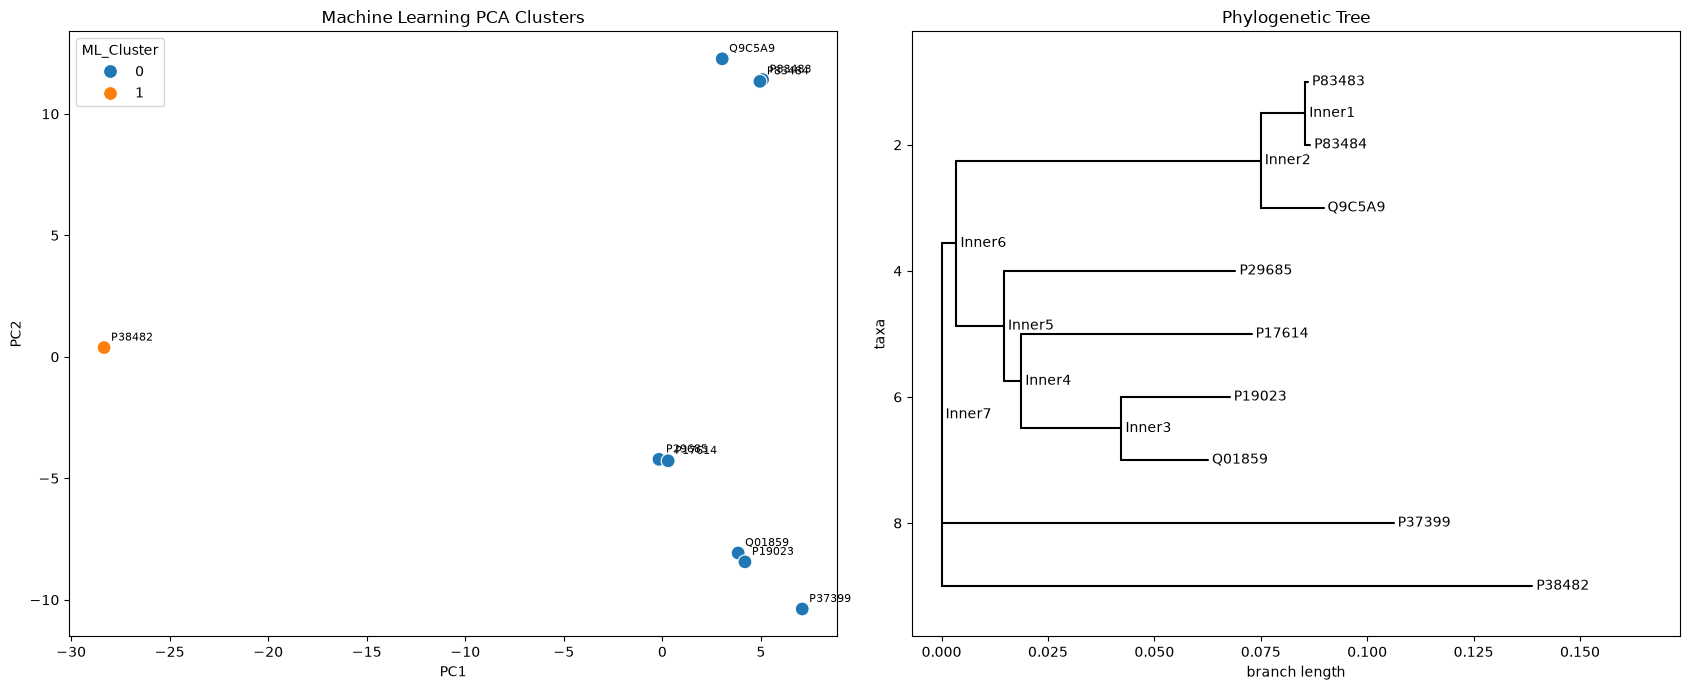

In [10]:
# CELL 14: FINAL VISUALIZATION

fig, axes = plt.subplots(1, 2, figsize=(17, 7))


# PCA plot

sns.scatterplot(
    data=ml_results,
    x="PC1",
    y="PC2",
    hue="ML_Cluster",
    palette="tab10",
    s=100,
    ax=axes[0]
)

for _, r in ml_results.iterrows():
    axes[0].annotate(r["Accession"], (r["PC1"], r["PC2"]),
                     textcoords="offset points", xytext=(5, 5), fontsize=8)

axes[0].set_title("Machine Learning PCA Clusters")


# Phylogenetic tree  (FIX: axes=axes[1], yoxsa ayri figur acilir)

Phylo.draw(
    tree,
    axes=axes[1],
    do_show=False,
    show_confidence=False
)

axes[1].set_title("Phylogenetic Tree")


plt.tight_layout()

plt.savefig(RESULTS_DIR / "final_comparison.png", dpi=300, bbox_inches="tight")

plt.show()

Saved: 85 x 78 mm, 600 dpi -> ARABIDOPSIS_ATP_SYNTHASE\results


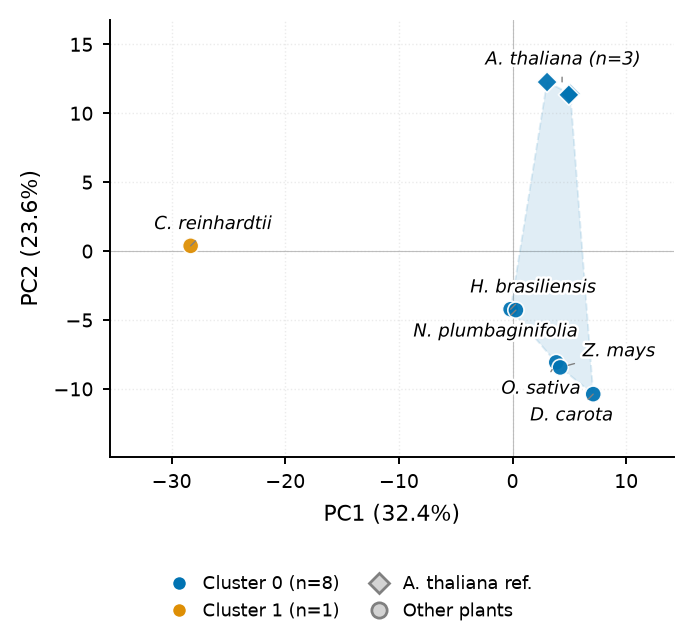

In [13]:
# CELL 8C: COMPACT PCA FIGURE FOR MANUSCRIPT

import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
from matplotlib.patches import Polygon
from scipy.spatial import ConvexHull

# ---------------- AYARLAR ----------------
FIG_WIDTH_MM = 85      # 85 = tək sütun, 120 = 1.5 sütun, 175 = tam səhifə eni
FIG_HEIGHT_MM = 78
SHOW_TITLE = False     # məqalədə başlıq adətən caption-da olur
SAVE_DPI = 600
# -----------------------------------------

FONT = 7               # əsas şrift ölçüsü (pt)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": FONT,
    "axes.linewidth": 0.7,
    "xtick.major.width": 0.7,
    "ytick.major.width": 0.7,
    "xtick.major.size": 2.5,
    "ytick.major.size": 2.5,
})

plot_df = ml_results.copy()


def short_name(organism):
    parts = organism.replace("subsp.", "").split()
    return f"{parts[0][0]}. {parts[1]}" if len(parts) >= 2 else organism


plot_df["Label"] = plot_df["Organism"].map(short_name)
plot_df["Is_Ref"] = plot_df["Accession"].isin(REFERENCE_ACCESSIONS)

clusters_present = sorted(plot_df["ML_Cluster"].unique())
palette = sns.color_palette("colorblind", n_colors=max(clusters_present) + 1)

fig, ax = plt.subplots(
    figsize=(FIG_WIDTH_MM / 25.4, FIG_HEIGHT_MM / 25.4), dpi=200
)

# 1) Klaster sahələri
for c in clusters_present:
    pts = plot_df.loc[plot_df["ML_Cluster"] == c, ["PC1", "PC2"]].values
    if len(pts) >= 3:
        try:
            hull = ConvexHull(pts)
            ax.add_patch(Polygon(
                pts[hull.vertices], closed=True,
                facecolor=palette[c], alpha=0.12,
                edgecolor=palette[c], linewidth=0.7, linestyle="--", zorder=1
            ))
        except Exception:
            pass

# 2) Nöqtələr
for is_ref, marker, size in [(True, "D", 28), (False, "o", 34)]:
    sub = plot_df[plot_df["Is_Ref"] == is_ref]
    if sub.empty:
        continue
    ax.scatter(
        sub["PC1"], sub["PC2"],
        c=[palette[i] for i in sub["ML_Cluster"]],
        marker=marker, s=size, edgecolor="white", linewidth=0.6,
        alpha=0.95, zorder=3
    )

# 3) Oxlar və grid
ev = pca.explained_variance_ratio_ * 100

ax.set_xlabel(f"PC1 ({ev[0]:.1f}%)", fontsize=FONT + 1)
ax.set_ylabel(f"PC2 ({ev[1]:.1f}%)", fontsize=FONT + 1)
ax.tick_params(labelsize=FONT)
ax.axhline(0, color="gray", lw=0.4, alpha=0.5, zorder=0)
ax.axvline(0, color="gray", lw=0.4, alpha=0.5, zorder=0)
ax.grid(alpha=0.25, linestyle=":", linewidth=0.5)
ax.margins(0.2)

for side in ("top", "right"):
    ax.spines[side].set_visible(False)

if SHOW_TITLE:
    ax.set_title("PCA of mitochondrial ATP synthase β-subunit",
                 loc="left", fontsize=FONT + 2, fontweight="bold")

# 4) Legenda şəklin altında (ölçünü böyütmür)
handles = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor=palette[c],
           markersize=5.5,
           label=f"Cluster {c} (n={int((plot_df['ML_Cluster'] == c).sum())})")
    for c in clusters_present
]
handles += [
    Line2D([0], [0], marker="D", color="w", markerfacecolor="lightgray",
           markeredgecolor="gray", markersize=5, label="A. thaliana ref."),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="lightgray",
           markeredgecolor="gray", markersize=5.5, label="Other plants"),
]
fig.legend(handles=handles, loc="lower center", ncol=2, frameon=False,
           fontsize=FONT - 0.5, columnspacing=1.2, handletextpad=0.3)

plt.tight_layout(rect=(0, 0.15, 1, 1), pad=0.4)

# 5) Etiketlər: eyni orqanizm = bir etiket; toqquşmayan mövqe avtomatik seçilir
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
px_per_pt = fig.dpi / 72

groups = (
    plot_df.groupby("Label")
    .agg(x=("PC1", "mean"), y=("PC2", "mean"), n=("Accession", "count"))
    .reset_index()
)

pt_r = 3.2 * px_per_pt     # nöqtənin qorunan radiusu
point_px = ax.transData.transform(plot_df[["PC1", "PC2"]].values)
point_boxes = [(px - pt_r, py - pt_r, px + pt_r, py + pt_r) for px, py in point_px]
ax_box = ax.get_window_extent()
pad = 1.2 * px_per_pt


def overlap(a, b):
    w = min(a[2], b[2]) - max(a[0], b[0])
    h = min(a[3], b[3]) - max(a[1], b[1])
    return max(w, 0) * max(h, 0)


center = np.array([groups["x"].mean(), groups["y"].mean()])
groups["_d"] = np.hypot(groups["x"] - center[0], groups["y"] - center[1])
placed_boxes = []

for _, g in groups.sort_values("_d").iterrows():

    label = g["Label"] + (f" (n={int(g['n'])})" if g["n"] > 1 else "")

    tmp = ax.text(0, 0, label, fontsize=FONT - 0.5, style="italic")
    bb = tmp.get_window_extent(renderer)
    w, h = bb.width, bb.height
    tmp.remove()

    gx, gy = ax.transData.transform((g["x"], g["y"]))

    best = None

    for radius_pt in (7, 11, 16, 22, 30):
        radius = radius_pt * px_per_pt
        for angle in np.linspace(0, 2 * np.pi, 24, endpoint=False):

            cx = gx + radius * np.cos(angle)
            cy = gy + radius * np.sin(angle)

            box = (cx - w / 2 - pad, cy - h / 2 - pad,
                   cx + w / 2 + pad, cy + h / 2 + pad)

            cost = radius_pt * 0.3
            cost += 50 * sum(overlap(box, b) for b in placed_boxes)
            cost += 50 * sum(overlap(box, b) for b in point_boxes)

            # Bağlayıcı xətt başqa nöqtədən/etiketdən keçməsin
            for t in np.linspace(0.2, 1.0, 12):
                sx = gx + t * (cx - gx)
                sy = gy + t * (cy - gy)
                for b in point_boxes:
                    own = np.hypot((b[0] + b[2]) / 2 - gx, (b[1] + b[3]) / 2 - gy) < pt_r
                    if not own and b[0] <= sx <= b[2] and b[1] <= sy <= b[3]:
                        cost += 300
                for b in placed_boxes:
                    if b[0] <= sx <= b[2] and b[1] <= sy <= b[3]:
                        cost += 300

            if (box[0] < ax_box.x0 or box[2] > ax_box.x1
                    or box[1] < ax_box.y0 or box[3] > ax_box.y1):
                cost += 1e7

            if best is None or cost < best[0]:
                best = (cost, cx - gx, cy - gy, box)

    _, dx_px, dy_px, box = best
    placed_boxes.append(box)

    ax.annotate(
        label, (g["x"], g["y"]),
        xytext=(dx_px / px_per_pt, dy_px / px_per_pt),
        textcoords="offset points",
        fontsize=FONT - 0.5, style="italic", ha="center", va="center", zorder=4,
        arrowprops=dict(arrowstyle="-", color="gray", lw=0.5,
                        shrinkA=1, shrinkB=3),
        path_effects=[pe.withStroke(linewidth=1.8, foreground="white")]
    )

# Dəqiq ölçü qorunur (bbox_inches="tight" işlədilmir)
fig.savefig(RESULTS_DIR / "PCA_manuscript.png", dpi=SAVE_DPI)
fig.savefig(RESULTS_DIR / "PCA_manuscript.pdf")
fig.savefig(RESULTS_DIR / "PCA_manuscript.tiff", dpi=SAVE_DPI)

print(f"Saved: {FIG_WIDTH_MM} x {FIG_HEIGHT_MM} mm, {SAVE_DPI} dpi -> {RESULTS_DIR}")
plt.show()

Saved: 85 x 74 mm, 600 dpi -> ARABIDOPSIS_ATP_SYNTHASE\results
Scale bar = substitutions/site (p-distance): 0.02


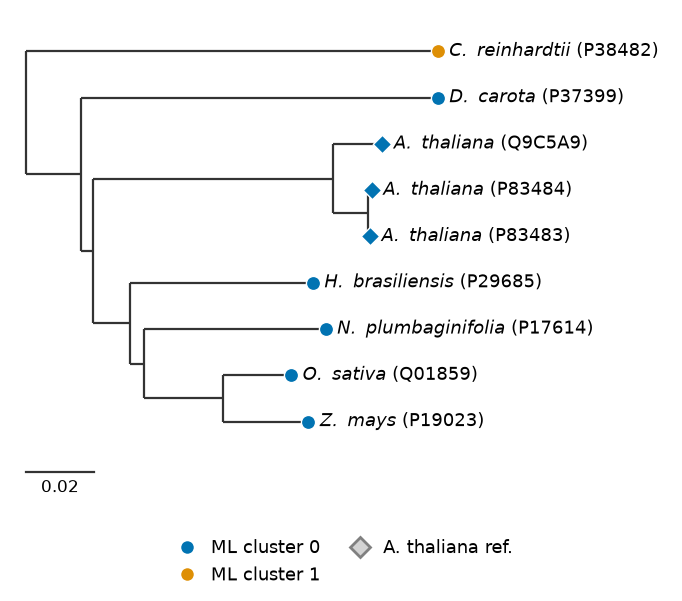

In [14]:
# CELL 9B: COMPACT PHYLOGENETIC TREE FOR MANUSCRIPT

import copy
import re
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D

# ---------------- AYARLAR ----------------
FIG_WIDTH_MM = 85       # 85 = tək sütun, 120 = 1.5 sütun, 175 = tam səhifə eni
FIG_HEIGHT_MM = None    # None = ağacın budaq sayına görə avtomatik
SAVE_DPI = 600
SHOW_SUPPORT = True     # bootstrap / aLRT dəyərləri (varsa)
SUPPORT_MIN = 0         # bu dəyərdən kiçik support göstərilməsin
# -----------------------------------------

FONT = 7

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": FONT,
    "mathtext.default": "regular",
})

# 1) Ağacı kopyala (orijinal `tree` dəyişmir), midpoint root et
plot_tree = copy.deepcopy(tree)

try:
    plot_tree.root_at_midpoint()
except Exception as error:
    print("Midpoint rooting alınmadı, ağac olduğu kimi çəkilir:", error)

plot_tree.ladderize()

# 2) Etiketlər və ML klaster rəngləri (PCA şəkli ilə eyni)
organism_lookup = clean_df.set_index("Accession")["Organism"].to_dict()

has_ml = "ml_results" in globals()
cluster_lookup = (
    dict(zip(ml_results["Accession"], ml_results["ML_Cluster"])) if has_ml else {}
)
n_clusters = (max(cluster_lookup.values()) + 1) if cluster_lookup else 1
palette = sns.color_palette("colorblind", n_colors=max(n_clusters, 1))


def short_name(organism):
    parts = organism.replace("subsp.", "").split()
    return f"{parts[0][0]}. {parts[1]}" if len(parts) >= 2 else organism


def tip_label(accession):
    organism = organism_lookup.get(accession)
    if not organism:
        return accession
    species = short_name(organism).replace(" ", r"\ ")
    return rf"$\mathit{{{species}}}$ ({accession})"


# 3) Koordinatlar: x = kökdən məsafə, y = budaq sırası
terminals = plot_tree.get_terminals()
n_tips = len(terminals)

x_pos, y_pos = {}, {}


def assign_x(clade, x):
    x_pos[clade] = x
    for child in clade.clades:
        assign_x(child, x + max(child.branch_length or 0, 0))


assign_x(plot_tree.root, 0.0)

tip_index = {}
for i, tip in enumerate(terminals):
    tip_index[tip] = i
    y_pos[tip] = i


def assign_y(clade):
    if clade.is_terminal():
        return y_pos[clade]
    ys = [assign_y(child) for child in clade.clades]
    y_pos[clade] = float(np.mean(ys))
    return y_pos[clade]


assign_y(plot_tree.root)

max_x = max(x_pos[t] for t in terminals)
if max_x <= 0:
    raise ValueError("Ağacda budaq uzunluqları sıfırdır, çəkmək mümkün deyil.")

# 4) Figur
height_mm = FIG_HEIGHT_MM or (20 + 6.0 * n_tips)

fig, ax = plt.subplots(
    figsize=(FIG_WIDTH_MM / 25.4, height_mm / 25.4), dpi=200
)
fig.subplots_adjust(left=0.02, right=0.98, top=0.98, bottom=0.17 if has_ml else 0.06)

LW = 0.8
line_color = "#333333"


def draw_clade(clade):
    if clade.clades:
        ys = [y_pos[c] for c in clade.clades]
        ax.plot([x_pos[clade]] * 2, [min(ys), max(ys)],
                color=line_color, lw=LW, solid_capstyle="butt", zorder=2)
    for child in clade.clades:
        ax.plot([x_pos[clade], x_pos[child]], [y_pos[child]] * 2,
                color=line_color, lw=LW, solid_capstyle="butt", zorder=2)
        draw_clade(child)


draw_clade(plot_tree.root)

# 5) Support dəyərləri
support_pattern = re.compile(r"^\d+(\.\d+)?(/\d+(\.\d+)?)?$")
support_texts = []

if SHOW_SUPPORT:
    for clade in x_pos:
        if clade.is_terminal() or clade is plot_tree.root:
            continue

        label = None

        if getattr(clade, "confidence", None) is not None:
            if clade.confidence >= SUPPORT_MIN:
                label = f"{clade.confidence:.0f}"
        elif clade.name and support_pattern.match(str(clade.name)):
            label = str(clade.name)

        if label:
            support_texts.append(ax.text(
                x_pos[clade], y_pos[clade] - 0.12, label,
                fontsize=FONT - 2, ha="right", va="bottom", color="#555555",
                zorder=4,
                path_effects=[pe.withStroke(linewidth=1.5, foreground="white")]
            ))

# 6) Tip markerləri və etiketlər
label_texts = []

for tip in terminals:

    accession = tip.name
    is_ref = accession in REFERENCE_ACCESSIONS
    cluster = cluster_lookup.get(accession)
    color = palette[cluster] if cluster is not None else "#444444"

    ax.scatter(
        x_pos[tip], y_pos[tip],
        marker="D" if is_ref else "o",
        s=22 if is_ref else 26,
        color=color, edgecolor="white", linewidth=0.5, zorder=5
    )

    label_texts.append(ax.text(
        x_pos[tip], y_pos[tip], "  " + tip_label(accession),
        fontsize=FONT - 0.5, ha="left", va="center", zorder=5
    ))

# 7) Etiketlər sığsın deyə x-limiti avtomatik hesabla
ax.set_ylim(n_tips + 0.5, -0.7)
ax.set_xlim(-0.01 * max_x, max_x * 2.0)
ax.axis("off")

fig.canvas.draw()
renderer = fig.canvas.get_renderer()

axes_px = ax.get_window_extent().width
needed = []

for tip, txt in zip(terminals, label_texts):
    w_px = txt.get_window_extent(renderer).width
    room = axes_px - w_px - 6
    if room > 0:
        needed.append(x_pos[tip] * axes_px / room)

x_right = max(needed) if needed else max_x * 2.0
ax.set_xlim(-0.01 * x_right, x_right)

# 8) Scale bar (kökdən aşağıda)
nice = [0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1.0]
scale = max([v for v in nice if v <= 0.35 * max_x] or [nice[0]])

bar_y = n_tips + 0.1
ax.plot([0, scale], [bar_y, bar_y], color=line_color, lw=LW, clip_on=False)
ax.text(scale / 2, bar_y + 0.15, f"{scale:g}", ha="center", va="top",
        fontsize=FONT - 1)

# 9) Legenda (PCA ilə eyni rənglər)
if has_ml:
    handles = [
        Line2D([0], [0], marker="o", color="w", markerfacecolor=palette[c],
               markersize=5.5, label=f"ML cluster {c}")
        for c in sorted(set(cluster_lookup.values()))
    ]
    handles.append(
        Line2D([0], [0], marker="D", color="w", markerfacecolor="lightgray",
               markeredgecolor="gray", markersize=5, label="A. thaliana ref.")
    )
    fig.legend(handles=handles, loc="lower center", ncol=2, frameon=False,
               fontsize=FONT - 0.5, columnspacing=1.2, handletextpad=0.3)

# Dəqiq ölçü qorunur (bbox_inches="tight" işlədilmir)
fig.savefig(RESULTS_DIR / "Tree_manuscript.png", dpi=SAVE_DPI)
fig.savefig(RESULTS_DIR / "Tree_manuscript.pdf")
fig.savefig(RESULTS_DIR / "Tree_manuscript.tiff", dpi=SAVE_DPI)

print(f"Saved: {FIG_WIDTH_MM} x {height_mm:.0f} mm, {SAVE_DPI} dpi -> {RESULTS_DIR}")
print("Scale bar = substitutions/site (p-distance):", scale)
plt.show()

Saved: 140 x 109 mm, 600 dpi -> ARABIDOPSIS_ATP_SYNTHASE\results
Scale bar = substitutions/site (p-distance): 0.02


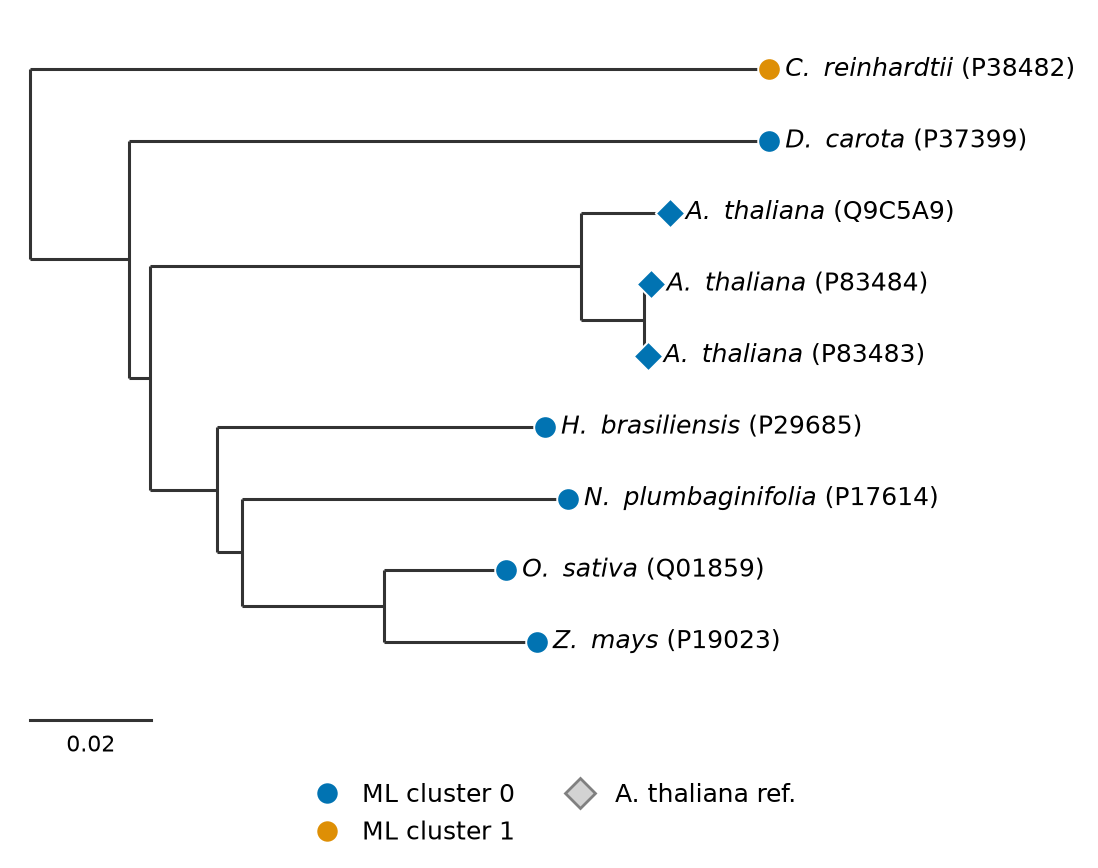

In [15]:
# CELL 9B: PHYLOGENETIC TREE FOR MANUSCRIPT (normal size)

import copy
import re
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D

# ---------------- AYARLAR ----------------
FIG_WIDTH_MM = 140      # 85 = tək sütun, 140 = normal, 175 = tam səhifə eni
FIG_HEIGHT_MM = None    # None = budaq sayına görə avtomatik
ROW_MM = 9              # hər budağa düşən hündürlük (mm) - sıx görünsə artır
FONT = 9                # şrift ölçüsü (pt)
SAVE_DPI = 600
SHOW_SUPPORT = True     # bootstrap / aLRT dəyərləri (varsa)
SUPPORT_MIN = 0         # bu dəyərdən kiçik support göstərilməsin
# -----------------------------------------

K = FONT / 7            # elementlərin şriftə uyğun miqyaslanması

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": FONT,
    "mathtext.default": "regular",
})

# 1) Ağacı kopyala (orijinal `tree` dəyişmir), midpoint root et
plot_tree = copy.deepcopy(tree)

try:
    plot_tree.root_at_midpoint()
except Exception as error:
    print("Midpoint rooting alınmadı, ağac olduğu kimi çəkilir:", error)

plot_tree.ladderize()

# 2) Etiketlər və ML klaster rəngləri (PCA şəkli ilə eyni)
organism_lookup = clean_df.set_index("Accession")["Organism"].to_dict()

has_ml = "ml_results" in globals()
cluster_lookup = (
    dict(zip(ml_results["Accession"], ml_results["ML_Cluster"])) if has_ml else {}
)
n_clusters = (max(cluster_lookup.values()) + 1) if cluster_lookup else 1
palette = sns.color_palette("colorblind", n_colors=max(n_clusters, 1))


def short_name(organism):
    parts = organism.replace("subsp.", "").split()
    return f"{parts[0][0]}. {parts[1]}" if len(parts) >= 2 else organism


def tip_label(accession):
    organism = organism_lookup.get(accession)
    if not organism:
        return accession
    species = short_name(organism).replace(" ", r"\ ")
    return rf"$\mathit{{{species}}}$ ({accession})"


# 3) Koordinatlar: x = kökdən məsafə, y = budaq sırası
terminals = plot_tree.get_terminals()
n_tips = len(terminals)

x_pos, y_pos, parent = {}, {}, {}


def assign_x(clade, x):
    x_pos[clade] = x
    for child in clade.clades:
        parent[child] = clade
        assign_x(child, x + max(child.branch_length or 0, 0))


assign_x(plot_tree.root, 0.0)

tip_index = {}
for i, tip in enumerate(terminals):
    tip_index[tip] = i
    y_pos[tip] = i


def assign_y(clade):
    if clade.is_terminal():
        return y_pos[clade]
    ys = [assign_y(child) for child in clade.clades]
    y_pos[clade] = float(np.mean(ys))
    return y_pos[clade]


assign_y(plot_tree.root)

max_x = max(x_pos[t] for t in terminals)
if max_x <= 0:
    raise ValueError("Ağacda budaq uzunluqları sıfırdır, çəkmək mümkün deyil.")

# 4) Figur
height_mm = FIG_HEIGHT_MM or (28 + ROW_MM * n_tips)

fig, ax = plt.subplots(
    figsize=(FIG_WIDTH_MM / 25.4, height_mm / 25.4), dpi=200
)
fig.subplots_adjust(left=0.02, right=0.98, top=0.98, bottom=0.13 if has_ml else 0.06)

LW = 1.1
line_color = "#333333"


def draw_clade(clade):
    if clade.clades:
        ys = [y_pos[c] for c in clade.clades]
        ax.plot([x_pos[clade]] * 2, [min(ys), max(ys)],
                color=line_color, lw=LW, solid_capstyle="butt", zorder=2)
    for child in clade.clades:
        ax.plot([x_pos[clade], x_pos[child]], [y_pos[child]] * 2,
                color=line_color, lw=LW, solid_capstyle="butt", zorder=2)
        draw_clade(child)


draw_clade(plot_tree.root)

# 5) Support dəyərləri
support_pattern = re.compile(r"^\d+(\.\d+)?(/\d+(\.\d+)?)?$")
support_items = []

if SHOW_SUPPORT:
    for clade in x_pos:
        if clade.is_terminal() or clade is plot_tree.root:
            continue

        label = None

        if getattr(clade, "confidence", None) is not None:
            if clade.confidence >= SUPPORT_MIN:
                label = f"{clade.confidence:.0f}"
        elif clade.name and support_pattern.match(str(clade.name)):
            label = str(clade.name)

        if label:
            support_items.append((clade, ax.text(
                x_pos[clade], y_pos[clade] - 0.1, label,
                fontsize=FONT - 1.5, ha="right", va="bottom", color="#555555",
                zorder=4,
                path_effects=[pe.withStroke(linewidth=2, foreground="white")]
            )))

# 6) Tip markerləri və etiketlər
label_texts = []

for tip in terminals:

    accession = tip.name
    is_ref = accession in REFERENCE_ACCESSIONS
    cluster = cluster_lookup.get(accession)
    color = palette[cluster] if cluster is not None else "#444444"

    ax.scatter(
        x_pos[tip], y_pos[tip],
        marker="D" if is_ref else "o",
        s=(34 if is_ref else 40) * K ** 2,
        color=color, edgecolor="white", linewidth=0.7, zorder=5
    )

    label_texts.append(ax.text(
        x_pos[tip], y_pos[tip], "  " + tip_label(accession),
        fontsize=FONT, ha="left", va="center", zorder=5
    ))

# 7) Etiketlər sığsın deyə x-limiti avtomatik hesabla
ax.set_ylim(n_tips + 0.5, -0.7)
ax.set_xlim(-0.01 * max_x, max_x * 2.0)
ax.axis("off")

fig.canvas.draw()
renderer = fig.canvas.get_renderer()

axes_px = ax.get_window_extent().width
needed = []

for tip, txt in zip(terminals, label_texts):
    w_px = txt.get_window_extent(renderer).width
    room = axes_px - w_px - 6
    if room > 0:
        needed.append(x_pos[tip] * axes_px / room)

x_right = max(needed) if needed else max_x * 2.0
ax.set_xlim(-0.01 * x_right, x_right)

# Support dəyəri qısa budağa sığmırsa, düyünün sağına keçir
fig.canvas.draw()
inv = ax.transData.inverted()

for clade, txt in support_items:
    p0 = ax.transData.transform((x_pos[parent[clade]], 0))[0]
    p1 = ax.transData.transform((x_pos[clade], 0))[0]
    w_px = txt.get_window_extent(renderer).width

    if (p1 - p0) < w_px + 4:
        txt.set_ha("left")
        txt.set_x(inv.transform((p1 + 4, 0))[0])

# 8) Scale bar (kökdən aşağıda)
nice = [0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1.0]
scale = max([v for v in nice if v <= 0.35 * max_x] or [nice[0]])

bar_y = n_tips + 0.1
ax.plot([0, scale], [bar_y, bar_y], color=line_color, lw=LW, clip_on=False)
ax.text(scale / 2, bar_y + 0.2, f"{scale:g}", ha="center", va="top",
        fontsize=FONT - 1)

# 9) Legenda (PCA ilə eyni rənglər)
if has_ml:
    handles = [
        Line2D([0], [0], marker="o", color="w", markerfacecolor=palette[c],
               markersize=6.5 * K, label=f"ML cluster {c}")
        for c in sorted(set(cluster_lookup.values()))
    ]
    handles.append(
        Line2D([0], [0], marker="D", color="w", markerfacecolor="lightgray",
               markeredgecolor="gray", markersize=6 * K, label="A. thaliana ref.")
    )
    fig.legend(handles=handles, loc="lower center", ncol=2, frameon=False,
               fontsize=FONT, columnspacing=1.6, handletextpad=0.4)

# Dəqiq ölçü qorunur (bbox_inches="tight" işlədilmir)
fig.savefig(RESULTS_DIR / "Tree_manuscript.png", dpi=SAVE_DPI)
fig.savefig(RESULTS_DIR / "Tree_manuscript.pdf")
fig.savefig(RESULTS_DIR / "Tree_manuscript.tiff", dpi=SAVE_DPI)

print(f"Saved: {FIG_WIDTH_MM} x {height_mm:.0f} mm, {SAVE_DPI} dpi -> {RESULTS_DIR}")
print("Scale bar = substitutions/site (p-distance):", scale)
plt.show()

Saved: 140 x 115 mm, 600 dpi -> ARABIDOPSIS_ATP_SYNTHASE\results


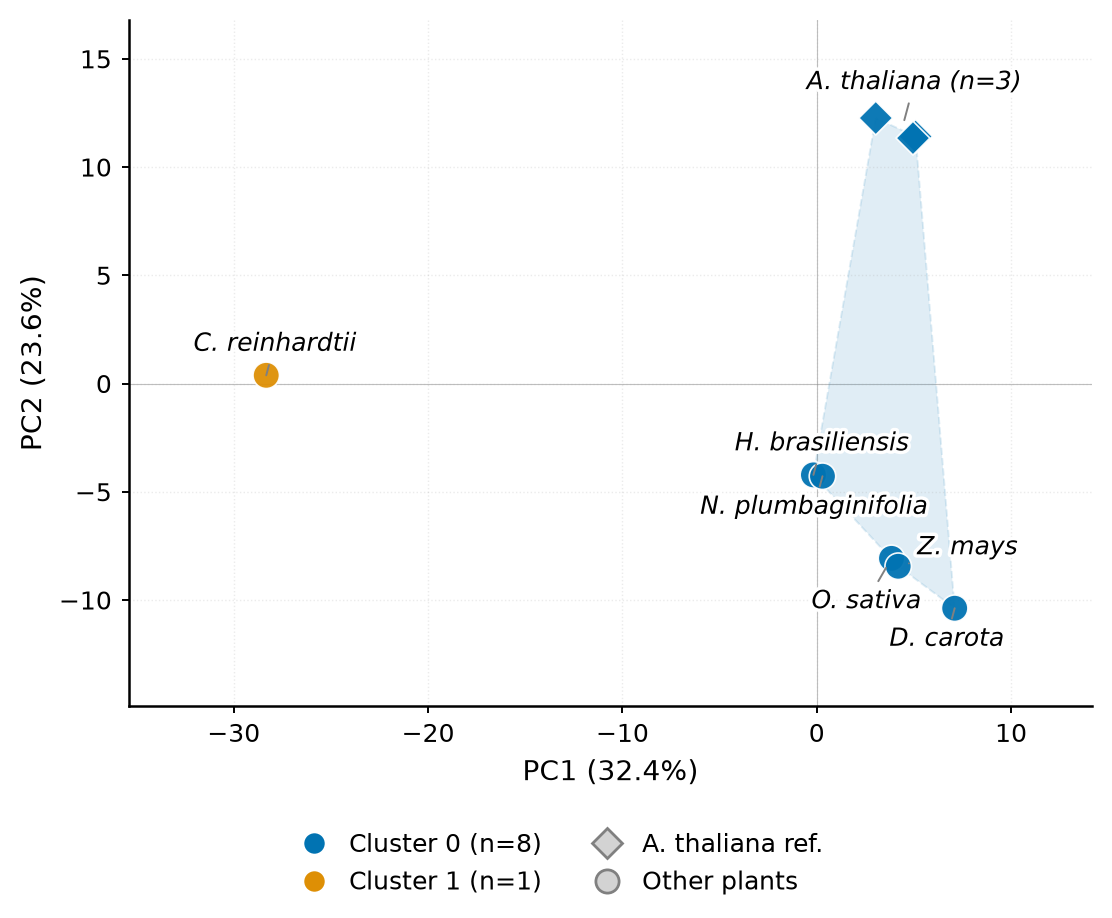

In [16]:
# CELL 8C: PCA FIGURE FOR MANUSCRIPT (normal size)

import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
from matplotlib.patches import Polygon
from scipy.spatial import ConvexHull

# ---------------- AYARLAR ----------------
FIG_WIDTH_MM = 140     # 85 = tək sütun, 140 = normal, 175 = tam səhifə eni
FIG_HEIGHT_MM = 115
FONT = 9               # şrift ölçüsü (pt)
SHOW_TITLE = False     # məqalədə başlıq adətən caption-da olur
SAVE_DPI = 600
# -----------------------------------------

K = FONT / 7           # elementlərin şriftə uyğun miqyaslanması

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": FONT,
    "axes.linewidth": 0.9,
    "xtick.major.width": 0.7,
    "ytick.major.width": 0.7,
    "xtick.major.size": 2.5,
    "ytick.major.size": 2.5,
})

plot_df = ml_results.copy()


def short_name(organism):
    parts = organism.replace("subsp.", "").split()
    return f"{parts[0][0]}. {parts[1]}" if len(parts) >= 2 else organism


plot_df["Label"] = plot_df["Organism"].map(short_name)
plot_df["Is_Ref"] = plot_df["Accession"].isin(REFERENCE_ACCESSIONS)

clusters_present = sorted(plot_df["ML_Cluster"].unique())
palette = sns.color_palette("colorblind", n_colors=max(clusters_present) + 1)

fig, ax = plt.subplots(
    figsize=(FIG_WIDTH_MM / 25.4, FIG_HEIGHT_MM / 25.4), dpi=200
)

# 1) Klaster sahələri
for c in clusters_present:
    pts = plot_df.loc[plot_df["ML_Cluster"] == c, ["PC1", "PC2"]].values
    if len(pts) >= 3:
        try:
            hull = ConvexHull(pts)
            ax.add_patch(Polygon(
                pts[hull.vertices], closed=True,
                facecolor=palette[c], alpha=0.12,
                edgecolor=palette[c], linewidth=0.7, linestyle="--", zorder=1
            ))
        except Exception:
            pass

# 2) Nöqtələr
for is_ref, marker, size in [(True, "D", 45 * K ** 2), (False, "o", 55 * K ** 2)]:
    sub = plot_df[plot_df["Is_Ref"] == is_ref]
    if sub.empty:
        continue
    ax.scatter(
        sub["PC1"], sub["PC2"],
        c=[palette[i] for i in sub["ML_Cluster"]],
        marker=marker, s=size, edgecolor="white", linewidth=0.6,
        alpha=0.95, zorder=3
    )

# 3) Oxlar və grid
ev = pca.explained_variance_ratio_ * 100

ax.set_xlabel(f"PC1 ({ev[0]:.1f}%)", fontsize=FONT + 1)
ax.set_ylabel(f"PC2 ({ev[1]:.1f}%)", fontsize=FONT + 1)
ax.tick_params(labelsize=FONT)
ax.axhline(0, color="gray", lw=0.4, alpha=0.5, zorder=0)
ax.axvline(0, color="gray", lw=0.4, alpha=0.5, zorder=0)
ax.grid(alpha=0.25, linestyle=":", linewidth=0.5)
ax.margins(0.2)

for side in ("top", "right"):
    ax.spines[side].set_visible(False)

if SHOW_TITLE:
    ax.set_title("PCA of mitochondrial ATP synthase β-subunit",
                 loc="left", fontsize=FONT + 2, fontweight="bold")

# 4) Legenda şəklin altında (ölçünü böyütmür)
handles = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor=palette[c],
           markersize=6.5 * K,
           label=f"Cluster {c} (n={int((plot_df['ML_Cluster'] == c).sum())})")
    for c in clusters_present
]
handles += [
    Line2D([0], [0], marker="D", color="w", markerfacecolor="lightgray",
           markeredgecolor="gray", markersize=6 * K, label="A. thaliana ref."),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="lightgray",
           markeredgecolor="gray", markersize=6.5 * K, label="Other plants"),
]
fig.legend(handles=handles, loc="lower center", ncol=2, frameon=False,
           fontsize=FONT, columnspacing=1.6, handletextpad=0.4)

plt.tight_layout(rect=(0, 0.12, 1, 1), pad=0.6)

# 5) Etiketlər: eyni orqanizm = bir etiket; toqquşmayan mövqe avtomatik seçilir
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
px_per_pt = fig.dpi / 72

groups = (
    plot_df.groupby("Label")
    .agg(x=("PC1", "mean"), y=("PC2", "mean"), n=("Accession", "count"))
    .reset_index()
)

pt_r = 3.6 * K * px_per_pt     # nöqtənin qorunan radiusu
point_px = ax.transData.transform(plot_df[["PC1", "PC2"]].values)
point_boxes = [(px - pt_r, py - pt_r, px + pt_r, py + pt_r) for px, py in point_px]
ax_box = ax.get_window_extent()
pad = 1.5 * K * px_per_pt


def overlap(a, b):
    w = min(a[2], b[2]) - max(a[0], b[0])
    h = min(a[3], b[3]) - max(a[1], b[1])
    return max(w, 0) * max(h, 0)


center = np.array([groups["x"].mean(), groups["y"].mean()])
groups["_d"] = np.hypot(groups["x"] - center[0], groups["y"] - center[1])
placed_boxes = []

for _, g in groups.sort_values("_d").iterrows():

    label = g["Label"] + (f" (n={int(g['n'])})" if g["n"] > 1 else "")

    tmp = ax.text(0, 0, label, fontsize=FONT, style="italic")
    bb = tmp.get_window_extent(renderer)
    w, h = bb.width, bb.height
    tmp.remove()

    gx, gy = ax.transData.transform((g["x"], g["y"]))

    best = None

    for radius_pt in (9, 14, 20, 28, 38):
        radius = radius_pt * K * px_per_pt
        for angle in np.linspace(0, 2 * np.pi, 24, endpoint=False):

            cx = gx + radius * np.cos(angle)
            cy = gy + radius * np.sin(angle)

            box = (cx - w / 2 - pad, cy - h / 2 - pad,
                   cx + w / 2 + pad, cy + h / 2 + pad)

            cost = radius_pt * 0.3
            cost += 50 * sum(overlap(box, b) for b in placed_boxes)
            cost += 50 * sum(overlap(box, b) for b in point_boxes)

            # Bağlayıcı xətt başqa nöqtədən/etiketdən keçməsin
            for t in np.linspace(0.2, 1.0, 12):
                sx = gx + t * (cx - gx)
                sy = gy + t * (cy - gy)
                for b in point_boxes:
                    own = np.hypot((b[0] + b[2]) / 2 - gx, (b[1] + b[3]) / 2 - gy) < pt_r
                    if not own and b[0] <= sx <= b[2] and b[1] <= sy <= b[3]:
                        cost += 300
                for b in placed_boxes:
                    if b[0] <= sx <= b[2] and b[1] <= sy <= b[3]:
                        cost += 300

            if (box[0] < ax_box.x0 or box[2] > ax_box.x1
                    or box[1] < ax_box.y0 or box[3] > ax_box.y1):
                cost += 1e7

            if best is None or cost < best[0]:
                best = (cost, cx - gx, cy - gy, box)

    _, dx_px, dy_px, box = best
    placed_boxes.append(box)

    ax.annotate(
        label, (g["x"], g["y"]),
        xytext=(dx_px / px_per_pt, dy_px / px_per_pt),
        textcoords="offset points",
        fontsize=FONT, style="italic", ha="center", va="center", zorder=4,
        arrowprops=dict(arrowstyle="-", color="gray", lw=0.7,
                        shrinkA=1, shrinkB=4),
        path_effects=[pe.withStroke(linewidth=2.5, foreground="white")]
    )

# Dəqiq ölçü qorunur (bbox_inches="tight" işlədilmir)
fig.savefig(RESULTS_DIR / "PCA_manuscript.png", dpi=SAVE_DPI)
fig.savefig(RESULTS_DIR / "PCA_manuscript.pdf")
fig.savefig(RESULTS_DIR / "PCA_manuscript.tiff", dpi=SAVE_DPI)

print(f"Saved: {FIG_WIDTH_MM} x {FIG_HEIGHT_MM} mm, {SAVE_DPI} dpi -> {RESULTS_DIR}")
plt.show()